In [2]:
import yfinance as yf


TICKERS = ["AAPL", "GOOGL", "AMZN", "KO", "JNJ", "JPM", "XOM", "CAT", "NEE", "LIN"]


raw = yf.download(
    TICKERS,
    period="3y",
    interval="1d",
    auto_adjust=True,
    threads=True,
    progress=False,
)
close = raw["Close"]
returns = close.pct_change(fill_method=None).dropna(how="any")
returns.index.name = "Date"
returns.to_csv("returns.csv")

print(f"Saved {len(returns)} rows")

Saved 752 rows


In [3]:
market_raw = yf.download(
    "^GSPC",
    period="3y",
    interval="1d",
    auto_adjust=True,
    threads=True,
    progress=False,
)
market_close = market_raw["Close"]["^GSPC"]
market_returns = market_close.pct_change(fill_method=None).dropna()
market_returns = market_returns.to_frame(name="^GSPC")
market_returns.index.name = "Date"
market_returns.to_csv("sp500_returns.csv")

print(f"Saved {len(market_returns)} rows")

Saved 752 rows


In [2]:
import pandas as pd

returns = pd.read_csv("returns.csv", parse_dates=True, index_col="Date")
market_returns = pd.read_csv("sp500_returns.csv", parse_dates=True, index_col="Date")

risk_free = pd.read_csv("TB3MS.csv", parse_dates=True, index_col="observation_date")
risk_free = risk_free.reindex(returns.index, method="ffill")

daily_risk_free = (1 + risk_free["TB3MS"] / 100) ** (1 / 252) - 1

excess_returns = returns.sub(daily_risk_free, axis=0)
market_excess_returns = market_returns.sub(daily_risk_free, axis=0)

In [3]:
from statsmodels.regression.rolling import RollingOLS


window = 252
market_excess = market_excess_returns.iloc[:, 0]
X = pd.DataFrame(
    {"intercept": 1.0, "market": market_excess},
    index=market_excess.index,
)

rolling_capm = []
for ticker in excess_returns.columns:
    y = excess_returns[ticker]
    fitted = RollingOLS(y, X, window=window).fit()
    params = fitted.params.rename(columns={"intercept": "Alpha", "market": "Beta"})
    params.insert(0, "Ticker", ticker)
    params = params.dropna(subset=["Alpha", "Beta"])
    rolling_capm.append(params)

rolling_capm = pd.concat(rolling_capm)

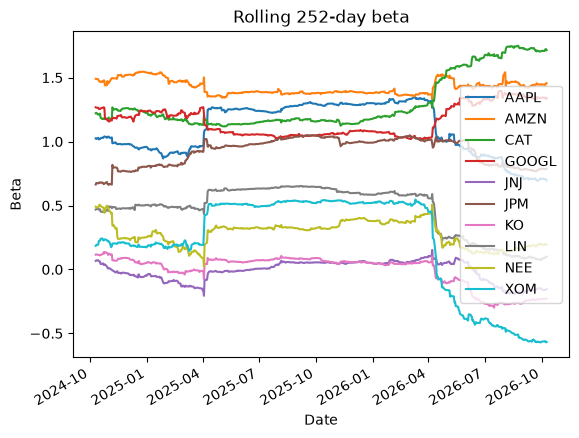

In [10]:
import matplotlib.pyplot as plt


beta = rolling_capm.pivot(columns="Ticker", values="Beta")
ax = beta.plot()
ax.set_title("Rolling 252-day beta")
ax.set_xlabel("Date")
ax.set_ylabel("Beta")
ax.legend(loc="center right")
plt.show()
